# 04 · Đánh giá tổng quát hóa và thực hành tại chỗ

Nhóm 13 · Bài kiểm tra 3 · Tiêu chí 7–10

Báo cáo Test chỉ gồm Logistic Regression của KT2 và ứng viên đã chốt
bằng ROC-AUC trung bình trên 5-fold CV của Train. PR-AUC trong bảng
được tính bằng average precision.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

for directory in (Path.cwd(), Path.cwd() / "code"):
    if (directory / "workflow_kt3.py").is_file():
        sys.path.insert(0, str(directory))
        break

from workflow_kt3 import ROOT, SUMMARY_PATH, load_splits

train, validation, test = load_splits()
with SUMMARY_PATH.open(encoding="utf-8") as summary_file:
    summary = json.load(summary_file)

In [2]:
import joblib
import numpy as np
from sklearn.model_selection import cross_val_score, train_test_split
from threadpoolctl import threadpool_limits
from workflow_kt3 import SEED, evaluate, get_model_score, make_hgb, stratified_cv, threshold_table

selection = summary["selection"]
chosen_id = selection["model_id"]
chosen = joblib.load(ROOT / "models" / selection["artifact"])
ids = ["baseline", chosen_id]
table = {}
for key in ids:
    cv_row = next(row for row in summary["cv_results"] if row["id"] == key)
    val_row = next(row for row in summary["val_results"] if row["id"] == key)
    test_row = next(row for row in summary["test_results"] if row["id"] == key)
    table[cv_row["Mô hình"]] = {
        "CV AUC": cv_row["CV ROC-AUC"], "Độ lệch chuẩn CV": cv_row["CV ROC-AUC std"],
        "Validation AUC": val_row["ROC-AUC"], "Test AUC": test_row["ROC-AUC"],
        "Test Accuracy": test_row["Accuracy"], "Test F1-Macro": test_row["F1-Macro"],
        "Test PR-AUC": test_row["PR-AUC"], "FP": test_row["FP"], "FN": test_row["FN"],
        "Độ trễ (ms/1.000 mẫu)": summary["latency_ms_per_1000_samples"][key],
    }
display(pd.DataFrame.from_dict(table, orient="index").round(5))

with threadpool_limits(1):
    checks = evaluate(test.y, chosen.predict(test.X), get_model_score(chosen, test.X))
for metric in ("ROC-AUC", "Accuracy", "F1-Macro", "FP", "FN"):
    np.testing.assert_allclose(checks[metric], test_row[metric], atol=1e-10)

,CV AUC,Độ lệch chuẩn CV,Validation AUC,Test AUC,Test Accuracy,Test F1-Macro,Test PR-AUC,FP,FN,Độ trễ (ms/1.000 mẫu)
Logistic Regression (KT2),0.94567,0.00238,0.94776,0.94404,0.86653,0.86498,0.95187,525,476,2.03037
"HistGradientBoosting + FE, tối ưu",0.98366,0.00113,0.98483,0.98343,0.92867,0.92786,0.98661,286,249,12.01900


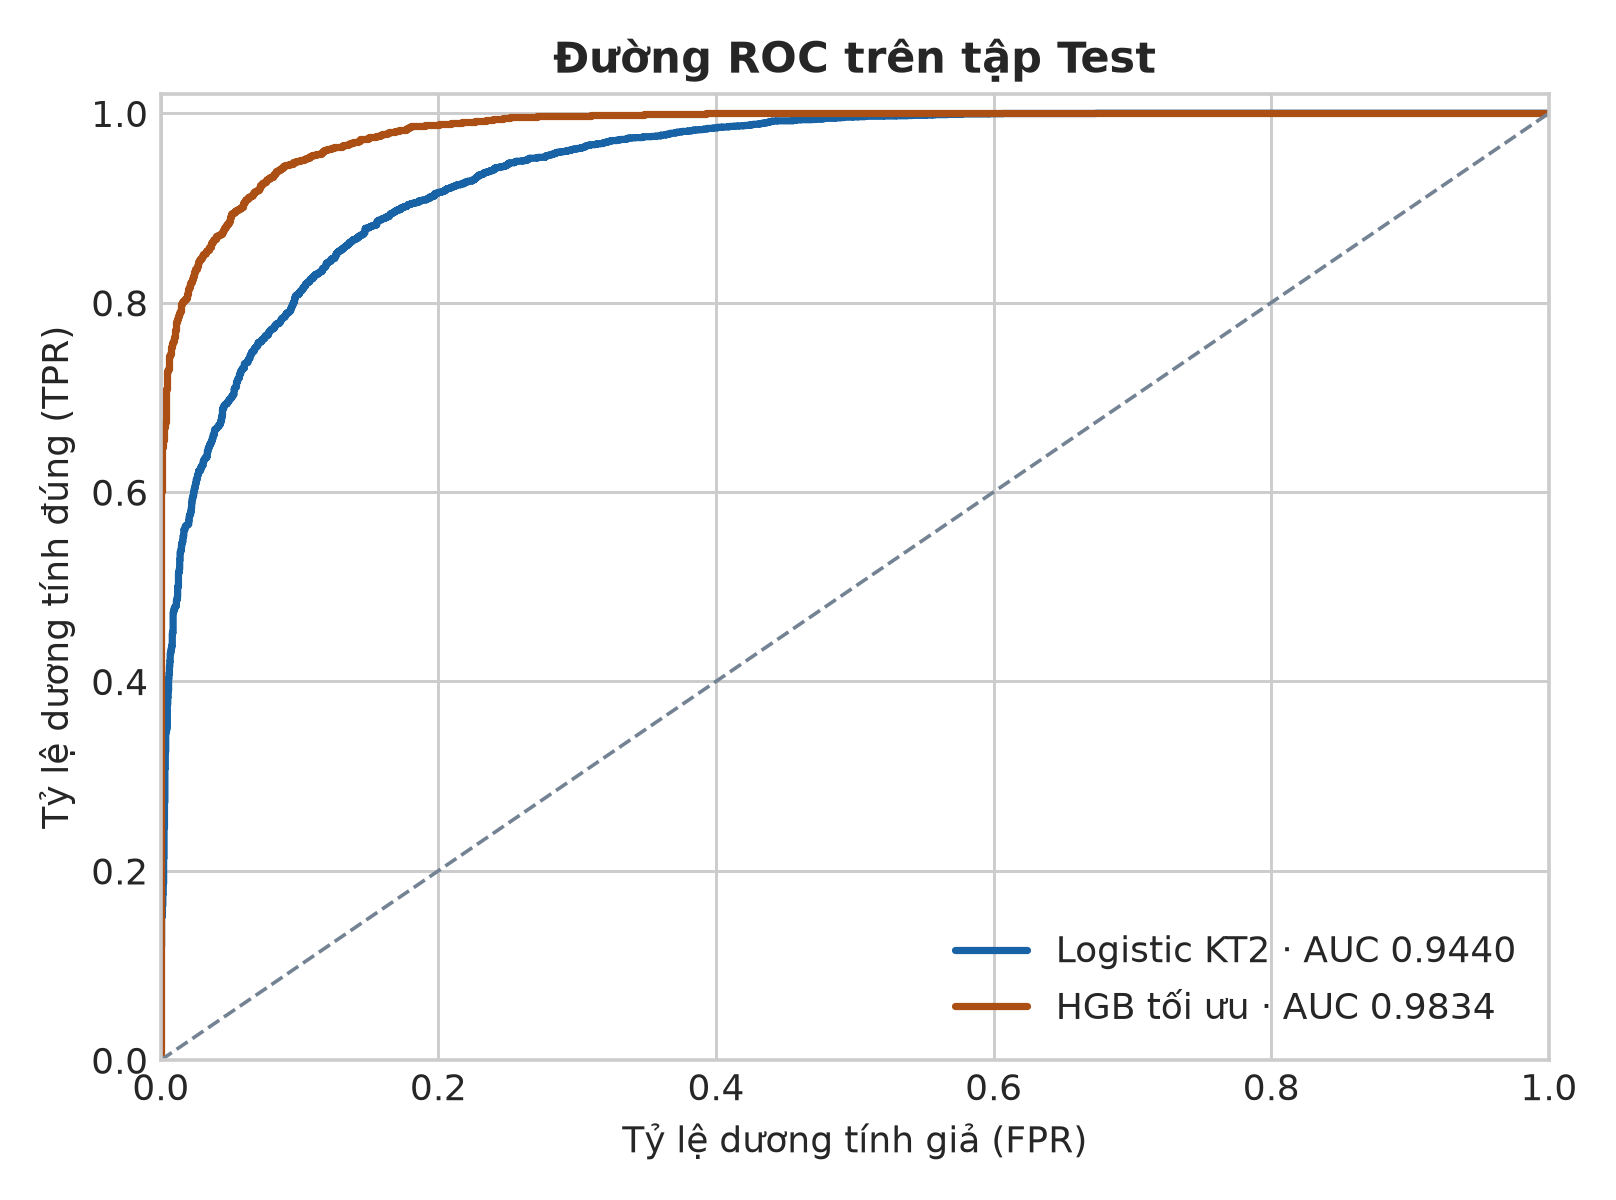

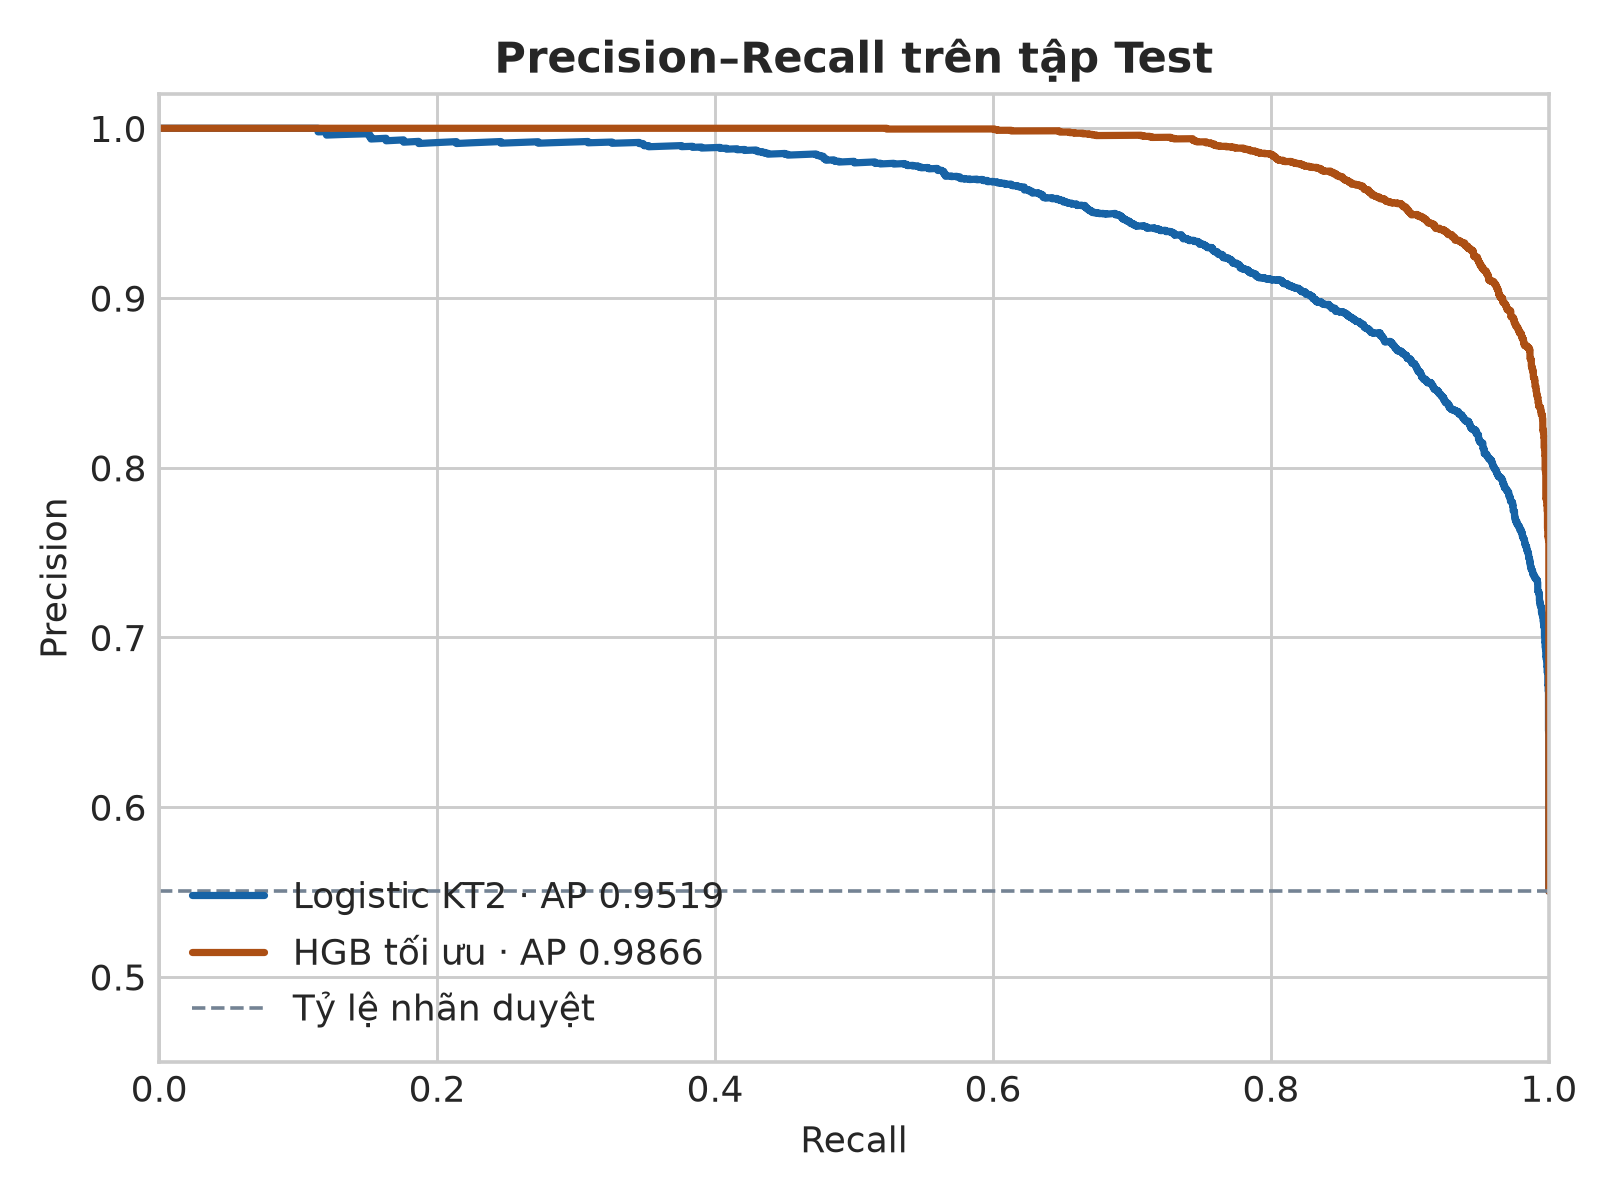

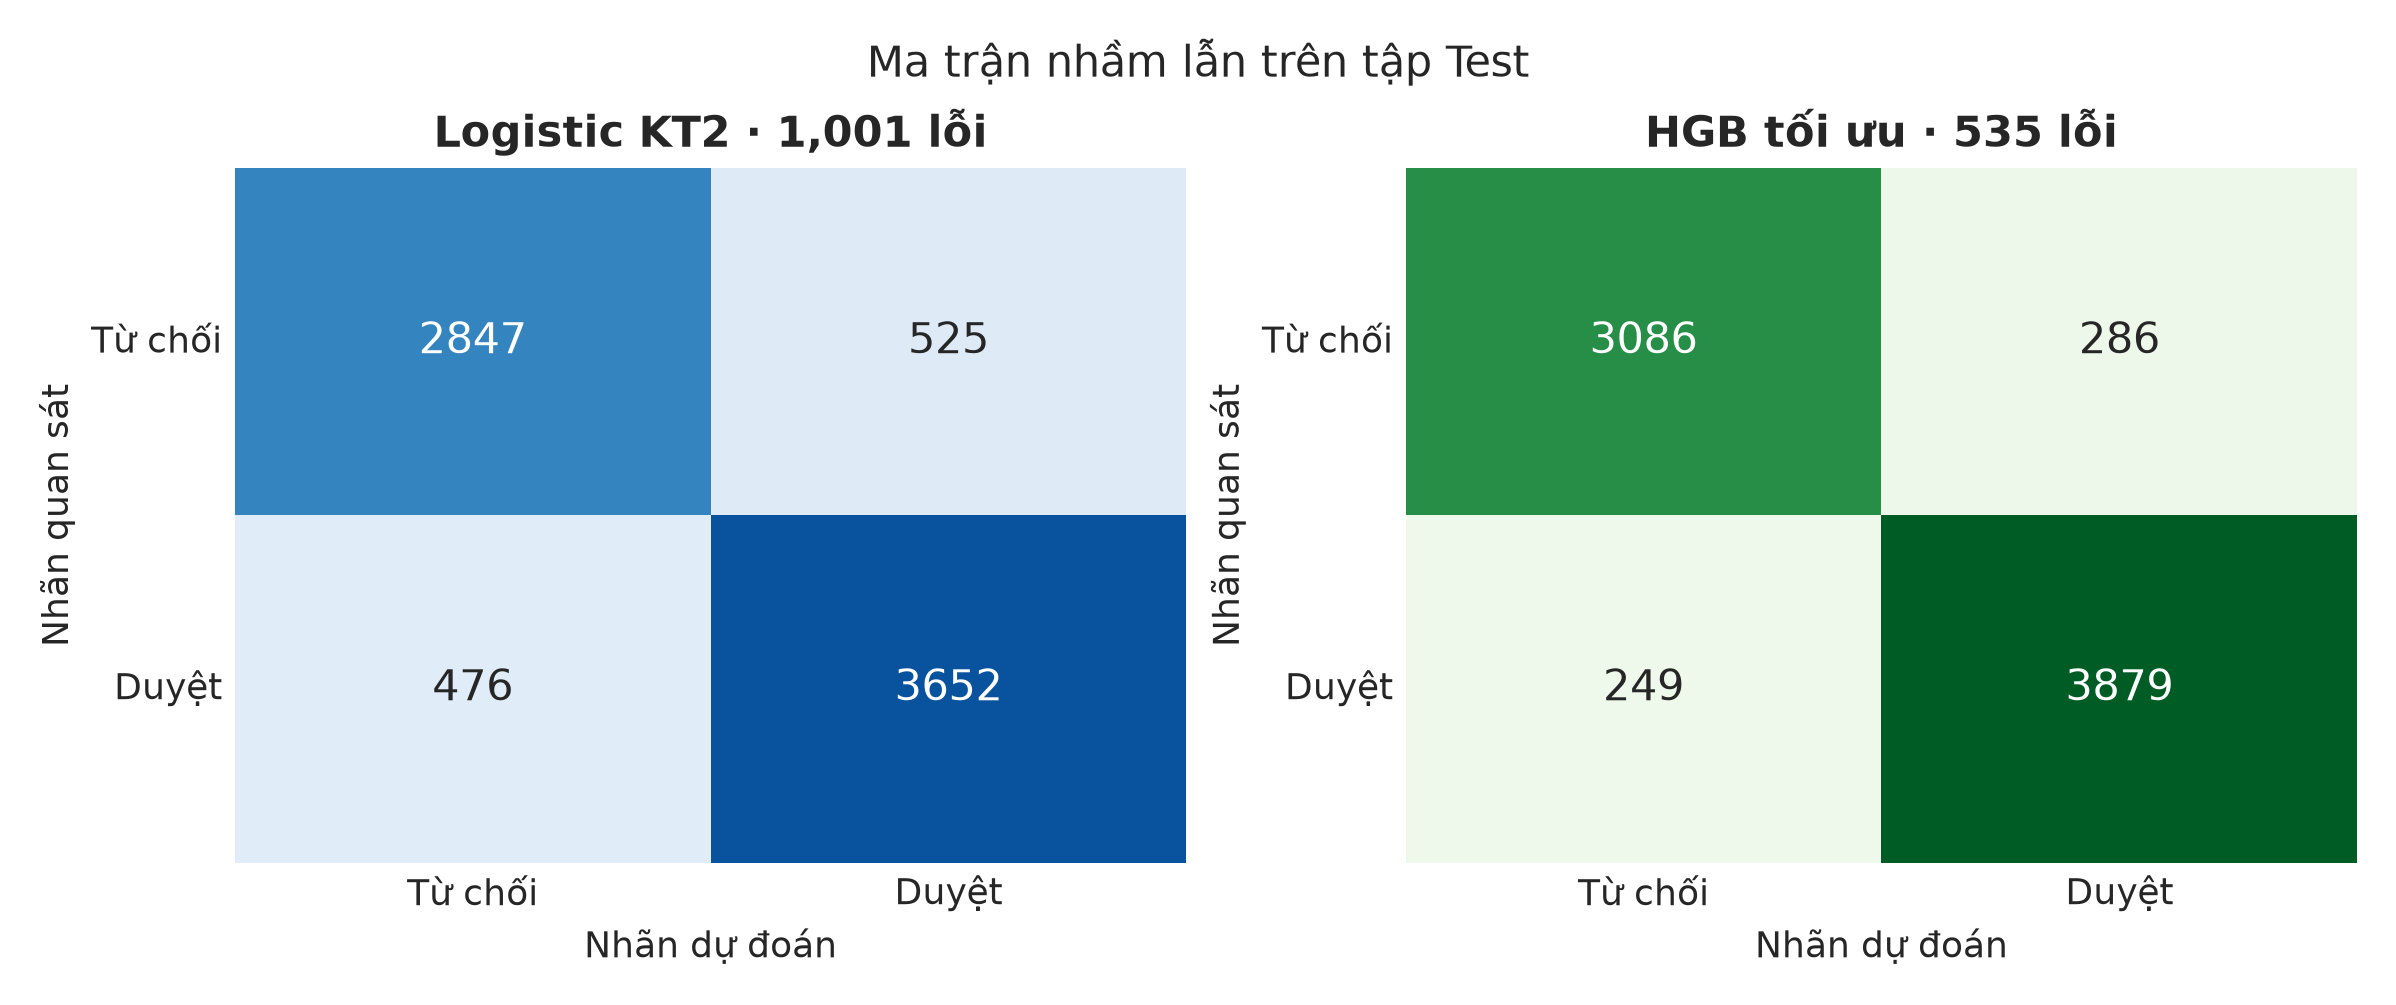

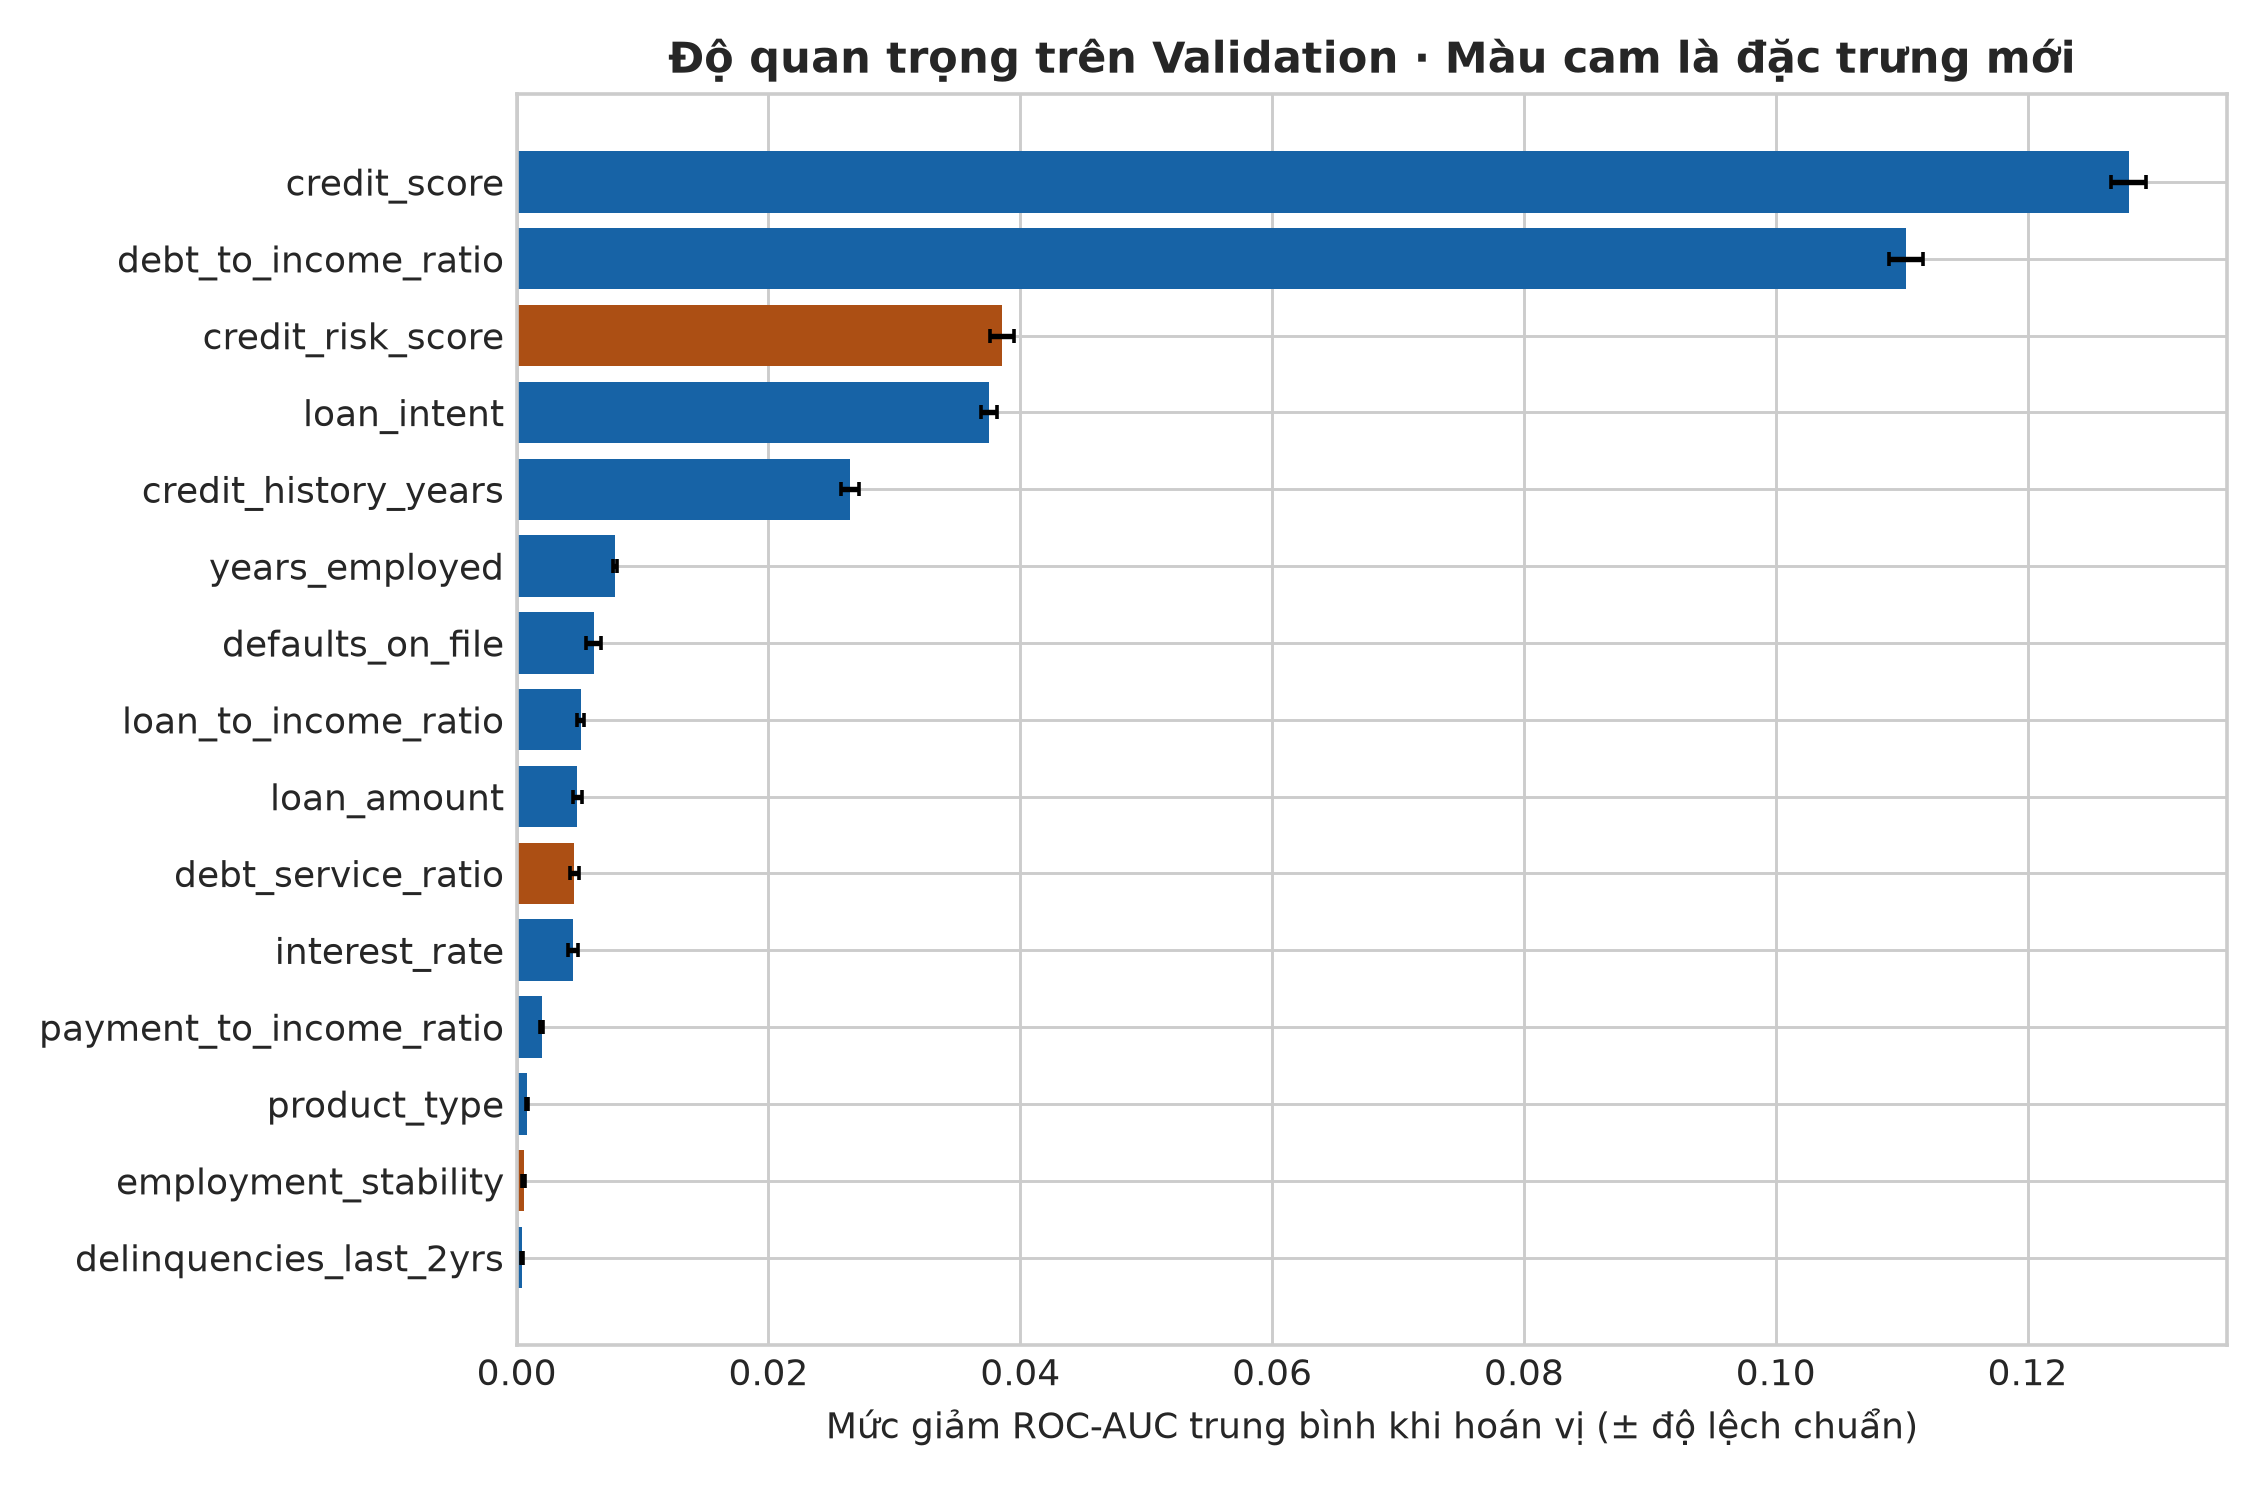

In [3]:
for figure in ("duong_cong_roc_so_sanh_kt3.png",
               "duong_cong_pr_so_sanh_kt3.png",
               "ma_tran_nham_lan_kt2_vs_kt3.png",
               "do_quan_trong_dac_trung_kt3.png"):
    display(Image(filename=str(ROOT / "images" / figure), width=760))

ROC-AUC phản ánh khả năng xếp hạng hai lớp. Ma trận nhầm lẫn cho thấy
sai số tại ngưỡng hiện hành. Độ trễ là trung vị của các lần gọi
predict trên cùng lô 1.000 hồ sơ Validation, bao gồm tiền xử lý.
Permutation Importance phản ánh mức phụ thuộc vào từng cột trên
Validation và có thể bị chia sẻ giữa các biến tương quan.

## Thực hành 1 · Quan sát ảnh hưởng của ngưỡng

Kiều Việt Anh. Trên Validation, so sánh 0,50 với 0,60 và giải thích
thay đổi của FP, FN, Specificity và Recall. Khi tăng ngưỡng, số dự đoán
duyệt giảm. Việc chọn một ngưỡng vận hành cần chi phí sai số hoặc ràng
buộc nghiệp vụ được xác định trước.

In [4]:
hgb = joblib.load(ROOT / "models" / "best_hist_gradient_boosting_pipeline.joblib")
with threadpool_limits(1):
    probabilities = hgb.predict_proba(validation.X)[:, 1]
threshold_table(validation.y, probabilities).round(4)

,Ngưỡng,FP,FN,Specificity,Recall
0,0.4,372,165,0.8896,0.9600
1,0.5,277,234,0.9178,0.9433
2,0.6,208,326,0.9383,0.9210
3,0.7,139,446,0.9588,0.8920


## Thực hành 2 · Đổi tốc độ học và chạy CV nhanh

Lương Chí Công. Lấy 15.000 hồ sơ có phân tầng từ Train. Giữ nguyên
3 fold và các siêu tham số còn lại, so sánh tốc độ học 0,08 với 0,15.
So sánh hai kết quả trên chính các fold này và đọc cả độ lệch chuẩn.

In [5]:
X_demo, _, y_demo, _ = train_test_split(
    train.X, train.y, train_size=15000, stratify=train.y, random_state=SEED
)
demo_rows = []
with threadpool_limits(1):
    for learning_rate in (0.08, 0.15):
        model = make_hgb(X_demo.columns, learning_rate=learning_rate)
        scores = cross_val_score(model, X_demo, y_demo, cv=stratified_cv(3), scoring="roc_auc")
        demo_rows.append({"learning_rate": learning_rate, "ROC-AUC": scores.mean(),
                          "Độ lệch chuẩn": scores.std()})
pd.DataFrame(demo_rows).round(5)

,learning_rate,ROC-AUC,Độ lệch chuẩn
0,0.08,0.98071,0.00170
1,0.15,0.98006,0.00164
